# Graph-level static action prediction

This notebook trains a graph-level PyTorch Geometric model on Pratt.

The learned target is static action through member axial force. Cross-section and material properties are not model inputs; the dataset assumes nominal constant values.

The limits below control both preprocessing time and dataset size. A different selection configuration creates a different file under `data/processed`, so a small development cache does not overwrite a larger experiment.


In [ ]:
from pathlib import Path
import copy
import os
import sys
import time

import numpy as np
import torch
from torch_geometric.loader import DataLoader

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
elif not (PROJECT_ROOT / "src").exists():
    raise RuntimeError("Run this notebook from root or root/notebooks.")

SRC_ROOT = PROJECT_ROOT / "src"
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))
from dataset import StaticActionDataset
from model import TrussAxialForceGNN
from training import (
    EpochSubsetSampler,
    checkpoint_path_for_config,
    load_model_checkpoint,
    save_model_checkpoint,
    collect_static_predictions,
    grouped_split, random_split,
    regression_metrics,
    run_axial_epoch,
    seed_everything,
)
from visualization import (
    plot_static_action_results,
    plot_training_history,
)
SEED = 42
seed_everything(SEED)

DATA_ROOT = PROJECT_ROOT / "data"
TYPOLOGIES = ["Pratt"]     # Selected missing folders are downloaded from Zenodo.
PANELS = None              # Example: [6, 8, 10]
MAX_SEEDS_PER_PANEL = None
MAX_DESIGNS_PER_SEED = None

BATCH_SIZE = 256
HIDDEN_DIM = 64
NUM_LAYERS = 4
DROPOUT = 0.05
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 1e-5
MAX_EPOCHS = 150
VALIDATE_EVERY = 5
PATIENCE_CHECKS = 20

TRAIN_GRAPHS_PER_EPOCH = None  # Example: 10_000
VAL_GRAPHS_PER_CHECK = None    # Example: 2_000

CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
CHECKPOINT_DIR.mkdir(exist_ok=True)

NUM_WORKERS = 0
torch.set_num_threads(max(1, os.cpu_count() or 1))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Project root:", PROJECT_ROOT)
print("Device:", DEVICE)
print("PyTorch CPU threads:", torch.get_num_threads())


Project root: root
Device: cpu
PyTorch CPU threads: 12


## Dataset

The dataset selects seed folders and designs **before opening JSON files**. Each selection configuration receives its own processed pickle, so changing the limits creates a separate cache automatically.

In [ ]:
dataset = StaticActionDataset(
    root=DATA_ROOT,
    typologies=TYPOLOGIES,
    panels=PANELS,
    max_seeds_per_panel=MAX_SEEDS_PER_PANEL,
    max_designs_per_seed=MAX_DESIGNS_PER_SEED,
    sampling_seed=SEED,
    force_reload=False,
)

print(f"Graphs: {len(dataset):,}")
print("Selection:", dataset.metadata["config"])
print("Typologies:", dataset.metadata["typologies"])
print("Node features:", dataset.metadata["node_feature_names"])
print("Directed edge features:", dataset.metadata["edge_feature_names"])
print("Member features:", dataset.metadata["member_feature_names"])
print("Processed cache:", dataset.processed_paths[0])

if len(dataset) < 3:
    raise RuntimeError("At least three selected graphs are required for training.")

sample = dataset[0]
print(sample)
print("Nodes:", sample.num_nodes)
print("Physical members:", sample.member_index.shape[1])
print("Directed message-passing edges:", sample.edge_index.shape[1])
print("Applied-load scale:", float(sample.load_scale))
print("True static action:", float(sample.static_action))
print("First five normalized targets:", sample.y[:5].tolist())


Graphs: 175,388
Selection: {'class': 'StaticActionDataset', 'process_version': 4, 'typologies': ('Pratt',), 'panels': None, 'seeds': None, 'max_seeds_per_panel': None, 'max_designs_per_seed': None, 'sampling_seed': 42, 'plane': 'xz'}
Typologies: ['Pratt']
Node features: ('coord_1_norm', 'coord_2_norm', 'load_1_norm', 'load_2_norm', 'is_free', 'degree_norm')
Directed edge features: ('delta_coord_1_norm', 'delta_coord_2_norm', 'length_norm')
Member features: ('length_norm', 'cos2', 'sin2', 'cos_sin')
Processed cache: root\data\processed\truss_axial_force_8bbdba6cd42a.pt
Data(x=[12, 6], edge_index=[2, 42], edge_attr=[42, 3], y=[21], member_index=[2, 21], member_attr=[21, 4], axial_force=[21], member_length=[21], load_scale=[1], static_action=[1], pos_raw=[12, 2], typology_id=[1], panels=[1], seed=[1], group_id=[1], graph_id=[1], num_members=[1])
Nodes: 12
Physical members: 21
Directed message-passing edges: 42
Applied-load scale: 1.0
True static action: 61.15253448486328
First five normal

## Splits and loaders

The train sampler visits only `TRAIN_GRAPHS_PER_EPOCH` graphs per epoch and draws a new subset on every pass. Validation uses a fixed smaller subset during model selection; final metrics still use the complete test split.

Training and validation loaders exclude tensors that are not needed by the loss, reducing collation and memory-copy overhead.


In [12]:
split = random_split(dataset, train_fraction=0.04, validation_fraction=0.10, seed=SEED) 

train_set = dataset[split.train]
val_set = dataset[split.validation]
test_set = dataset[split.test]

TRAIN_EXCLUDE_KEYS = [
    "axial_force", "member_length", "load_scale", "static_action",
    "pos_raw", "typology_id", "panels", "seed", "group_id",
    "graph_id", "num_members",
]

worker_kwargs = {"num_workers": NUM_WORKERS}
if NUM_WORKERS > 0:
    worker_kwargs.update(persistent_workers=True, prefetch_factor=2)

train_sampler = None
if TRAIN_GRAPHS_PER_EPOCH is not None:
    train_sampler = EpochSubsetSampler(len(train_set), TRAIN_GRAPHS_PER_EPOCH, seed=SEED + 1)

val_sampler = None
if VAL_GRAPHS_PER_CHECK is not None:
    val_sampler = EpochSubsetSampler(len(val_set), VAL_GRAPHS_PER_CHECK, seed=SEED + 2)

train_loader = DataLoader(
    train_set,
    batch_size=BATCH_SIZE,
    sampler=train_sampler,
    shuffle=train_sampler is None,
    drop_last=train_sampler is not None,
    exclude_keys=TRAIN_EXCLUDE_KEYS,
    pin_memory=torch.cuda.is_available(),
    **worker_kwargs,
)
val_loader = DataLoader(
    val_set,
    batch_size=BATCH_SIZE,
    sampler=val_sampler,
    shuffle=False,
    exclude_keys=TRAIN_EXCLUDE_KEYS,
    pin_memory=torch.cuda.is_available(),
    **worker_kwargs,
)
test_loader = DataLoader(
    test_set,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=torch.cuda.is_available(),
    **worker_kwargs,
)

print(f"Full train split: {len(train_set):,}")
print(f"Full validation split: {len(val_set):,}")
print(f"Full test split: {len(test_set):,}")
print(f"Training batches per epoch: {len(train_loader):,}")


Full train split: 7,016
Full validation split: 17,539
Full test split: 150,833
Training batches per epoch: 28


## Model and training

The model uses residual `MPNN` layers. Unlike a plain GCN, MPNN incorporates the directed geometric edge attributes during message passing.

Each graph can contain a different number of members. The loss first averages member errors inside each graph and then averages across graphs, preventing larger trusses from dominating solely because they have more edges.

Trainable parameters: 146,305
Loaded checkpoint: root\checkpoints\truss_axial_force_gnn_0282d0f5ab49.pt


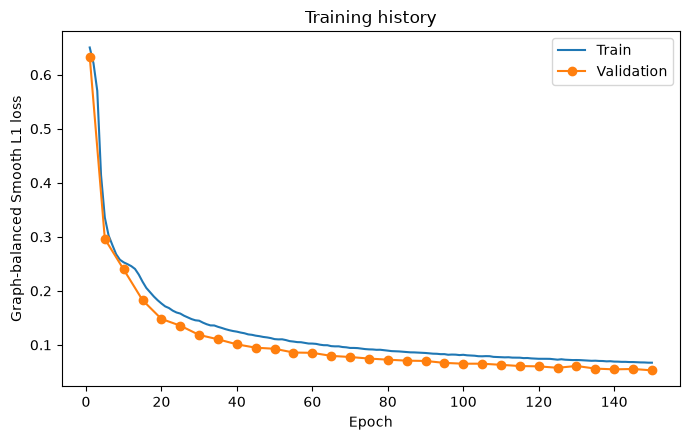

Mean epoch time: 14.7s


In [13]:
model_config = {
    "node_dim": sample.x.shape[-1],
    "directed_edge_dim": sample.edge_attr.shape[-1],
    "member_dim": sample.member_attr.shape[-1],
    "hidden_dim": HIDDEN_DIM,
    "num_layers": NUM_LAYERS,
    "dropout": DROPOUT,
}
model = TrussAxialForceGNN(**model_config).to(DEVICE)
checkpoint_path = checkpoint_path_for_config(
    CHECKPOINT_DIR,
    "truss_axial_force_gnn",
    dataset.metadata,
    model_config,
    seed=SEED,
)
checkpoint = load_model_checkpoint(checkpoint_path, model, DEVICE)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

if checkpoint is not None:
    history = checkpoint.get("history") or {"train": [], "val": [], "lr": [], "seconds": []}
    best_val = float(checkpoint.get("best_validation_loss", "nan"))
    print("Loaded checkpoint:", checkpoint_path)
else:
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2, min_lr=1e-6
    )
    history = {"train": [], "val": [], "lr": [], "seconds": []}
    best_state = None
    best_val = float("inf")
    patience_counter = 0

    for epoch in range(1, MAX_EPOCHS + 1):
        start = time.perf_counter()
        train_loss = run_axial_epoch(model, train_loader, optimizer, DEVICE)
        should_validate = epoch == 1 or epoch % VALIDATE_EVERY == 0 or epoch == MAX_EPOCHS

        if should_validate:
            val_loss = run_axial_epoch(model, val_loader, None, DEVICE)
            scheduler.step(val_loss)
            if val_loss < best_val:
                best_val = val_loss
                best_state = copy.deepcopy(model.state_dict())
                patience_counter = 0
            else:
                patience_counter += 1
        else:
            val_loss = float("nan")

        elapsed = time.perf_counter() - start
        learning_rate = optimizer.param_groups[0]["lr"]
        history["train"].append(train_loss)
        history["val"].append(val_loss)
        history["lr"].append(learning_rate)
        history["seconds"].append(elapsed)

        if should_validate or epoch % 5 == 0:
            val_text = f"{val_loss:.6f}" if should_validate else "skipped"
            print(f"Epoch {epoch:03d} | train={train_loss:.6f} | val={val_text} | lr={learning_rate:.2e} | {elapsed:.1f}s")

        if should_validate and patience_counter >= PATIENCE_CHECKS:
            print(f"Early stopping at epoch {epoch}; best validation loss={best_val:.6f}")
            break

    if best_state is None:
        raise RuntimeError("Training did not produce a validated model state.")
    model.load_state_dict(best_state)
    save_model_checkpoint(
        checkpoint_path,
        model,
        model_config=model_config,
        dataset_metadata=dataset.metadata,
        best_validation_loss=best_val,
        seed=SEED,
        history=history,
    )
    print("Saved:", checkpoint_path)

if history.get("train"):
    plot_training_history(history)
    if history.get("seconds"):
        print(f"Mean epoch time: {np.mean(history['seconds']):.1f}s")
else:
    print("Training history is not available in this checkpoint.")


## Evaluation

Metrics are reported in the original physical displacement units and only over **free nodes**.

- **MAE — Mean Absolute Error:** average absolute prediction error. It is easy to interpret in the displacement unit and is less sensitive to a small number of large errors than RMSE.
- **RMSE — Root Mean Squared Error:** square root of the mean squared error. It penalizes large errors more strongly and is useful for identifying occasional poor predictions.
- **$R^2$ — Coefficient of determination:** compares the residual variance with the variance of the true targets. A value of 1 is perfect, 0 is equivalent to predicting the test-set mean, and a negative value is worse than that constant baseline.

static action metrics
  MAE: 5.96728
  RMSE: 8.56735
  R2: 0.709508


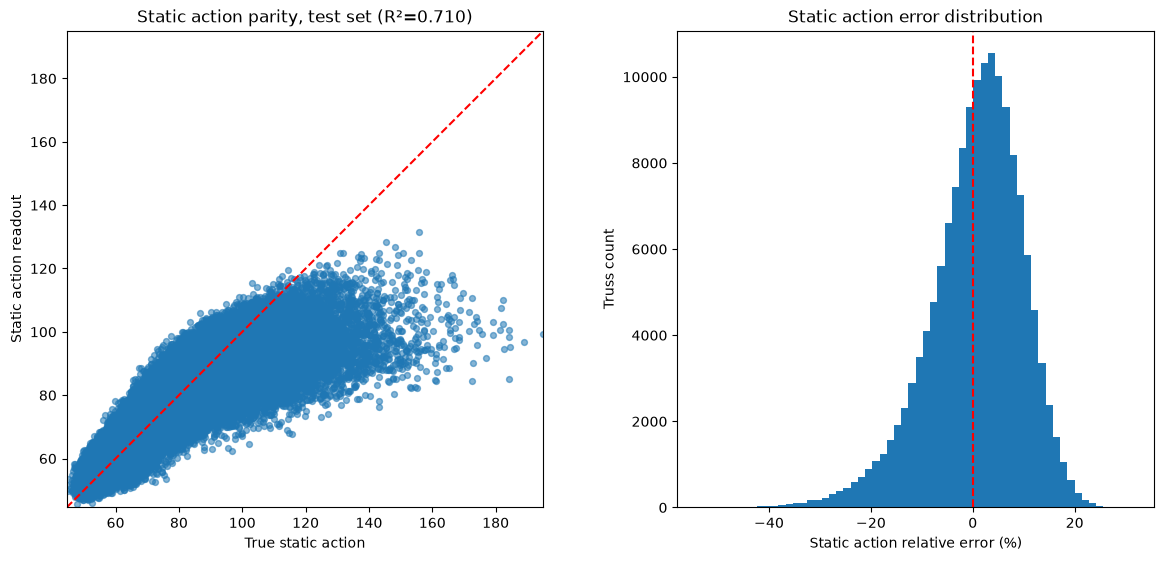

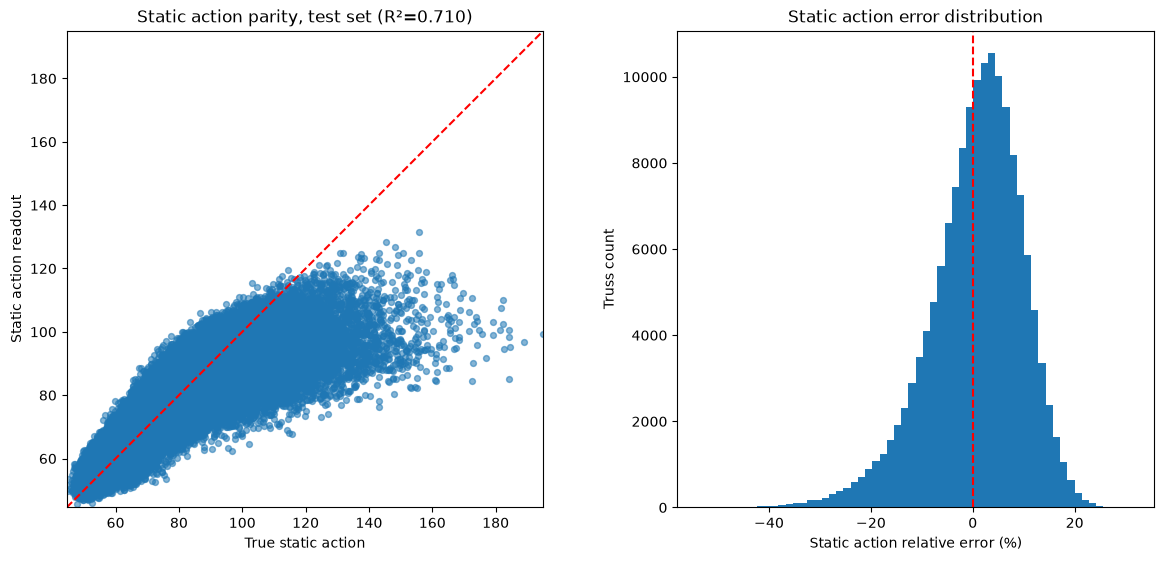

In [14]:
predictions = collect_static_predictions(model, test_loader, DEVICE)
static_metrics = regression_metrics(predictions["static_true"], predictions["static_pred"])

print("static action metrics")
for name, value in static_metrics.items():
    print(f"  {name}: {value:.6g}")

plot_static_action_results(predictions, static_metrics['R2'])


## Save checkpoint


In [15]:
print("Checkpoint path:", checkpoint_path)


Checkpoint path: root\checkpoints\truss_axial_force_gnn_0282d0f5ab49.pt
